# Model Benchmark

So sánh toàn bộ các mô hình dự báo số yêu cầu bảo trì cây **tuần tới** cho từng khu phố, trên **9 mốc kiểm tra** (Notebook 1, mục 7), để trả lời:
- **RQ2:** mô hình nền tảng zero-shot có dự báo chính xác hơn mô hình huấn luyện riêng không — trên nhiều mốc thời gian, trên khu phố ít lẫn nhiều yêu cầu? Dữ liệu ngoài (thời tiết, giấy phép thi công) có giúp gì không?
- **RQ3:** mỗi họ mô hình chịu tác động của điểm gãy 2024 ra sao, và tái huấn luyện định kỳ có giúp thích ứng không?

**Dữ liệu đầu vào:**
- `SF_Tree_Weekly_Features.csv` (Notebook 3): đặc trưng trễ và biến mục tiêu cho ba biến đếm `n`, `n_all`, `n_damaged`.
- `SF_Tree_Weekly_Data_Cleaned.csv` (Notebook 2): chuỗi số yêu cầu theo tuần của từng khu phố, làm ngữ cảnh cho mô hình nền tảng.
- `regime_05_test_origins.csv` (Notebook 6): giai đoạn của từng mốc kiểm tra so với điểm gãy.

**Các mô hình** (Notebook 1, mục 6):

| Họ mô hình | Mô hình | Cần huấn luyện? | Dùng biến ngoài? |
|---|---|---|---|
| Mốc đơn giản | Lặp lại tuần trước; Trung bình 4 tuần; Cùng tuần năm trước | Không | Không |
| Mô hình đếm | Hồi quy Poisson | Có | Có |
| Học máy | Ridge; Random Forest; LightGBM | Có | Có |
| Mô hình nền tảng zero-shot | Chronos-Bolt Small; Chronos-Bolt Base; Chronos-2; TimesFM 2.5 | Không | Không |
| Mô hình nền tảng zero-shot có biến ngoài | Chronos-2 + biến ngoài | Không | Có |

Notebook chạy khoảng 20–30 phút trên máy có GPU; phần lớn thời gian dành cho Random Forest và các thử nghiệm tái huấn luyện.

## **1. Khởi tạo và nạp dữ liệu**

In [1]:
# Nếu thiếu thư viện, chạy 1 lần: pip install scikit-learn lightgbm "chronos-forecasting>=2.2" "timesfm[torch]"
import os
os.environ["HF_HUB_DISABLE_XET"] = "1"   # tắt kiểu tải mới hay bị kẹt
os.environ["HF_HUB_OFFLINE"] = "1"       # chỉ dùng mô hình đã tải sẵn trong máy, không tải lại
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import lightgbm as lgb
import torch

import warnings
warnings.filterwarnings("ignore")
sns.set_style("ticks")
os.makedirs("../Outputs/figures", exist_ok=True)
os.makedirs("../Outputs/tables", exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Thiết bị chạy mô hình nền tảng:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

Thiết bị chạy mô hình nền tảng: cuda NVIDIA GeForce RTX 2050


In [2]:
# Cấu hình chung (khớp Notebook 1, mục 7)
MOC_KIEM_TRA = pd.to_datetime(["2022-01-03", "2022-07-04", "2023-01-02", "2023-07-03", "2024-01-01",
                               "2024-07-01", "2025-01-06", "2025-07-07", "2026-01-05"])
SO_TUAN_KIEM_TRA = 26
MOC_KIEM_DINH = pd.Timestamp("2021-07-05")      # 26 tuần ngay trước mốc kiểm tra đầu tiên, dùng để tinh chỉnh tham số
TUAN_DEM = pd.Timedelta(days=7)                 # tuần đệm giữa tập huấn luyện và tập kiểm tra

# Ba biến đếm và biến mục tiêu (số yêu cầu tuần tới) tương ứng
BIEN_DEM = {"n": "y_next", "n_all": "y_next_all", "n_damaged": "y_next_damaged"}
TEN_BIEN = {"n": "n (đã loại trùng)", "n_all": "n_all (giữ cả trùng)", "n_damaged": "n_damaged (cây hư hại)"}

feat = pd.read_csv("../Data/processed/SF_Tree_Weekly_Features.csv", parse_dates=["week_start"])
feat = feat.sort_values(["nbhd", "week_start"]).reset_index(drop=True)
feat["nbhd_code"] = feat["nbhd"].astype("category").cat.codes    # mã số khu phố cho mô hình

weekly = pd.read_csv("../Data/processed/SF_Tree_Weekly_Data_Cleaned.csv", parse_dates=["week_start"])
weekly = weekly.sort_values(["nbhd", "week_start"]).reset_index(drop=True)

giai_doan = pd.read_csv("../Outputs/tables/regime_05_test_origins.csv", parse_dates=["moc_kiem_tra"])
GIAI_DOAN = dict(zip(giai_doan["moc_kiem_tra"], giai_doan["giai_doan"]))

print("Bảng đặc trưng:", feat.shape)
print("Bảng tuần     :", weekly.shape)
giai_doan[["moc_kiem_tra", "tuan_cuoi", "giai_doan"]]

Bảng đặc trưng: (25174, 34)
Bảng tuần     : (25174, 15)


,moc_kiem_tra,tuan_cuoi,giai_doan
0,2022-01-03,2022-06-27,Trước điểm gãy
1,2022-07-04,2022-12-26,Trước điểm gãy
2,2023-01-02,2023-06-26,Trước điểm gãy
3,2023-07-03,2023-12-25,Trước điểm gãy
4,2024-01-01,2024-06-24,Chứa điểm gãy
5,2024-07-01,2024-12-23,Sau điểm gãy
6,2025-01-06,2025-06-30,Sau điểm gãy
7,2025-07-07,2025-12-29,Sau điểm gãy
8,2026-01-05,2026-06-29,Sau điểm gãy


In [3]:
def nhom_dac_trung(bien):
    """Các nhóm đặc trưng cho biến đếm `bien` (n, n_all hoặc n_damaged)."""
    return {
        "Lịch sử nhu cầu":    [bien, f"{bien}_lag1", f"{bien}_lag2", f"{bien}_lag52", f"{bien}_ma4"],
        "Giấy phép thi công": ["permits_active"],
        "Thời tiết":          ["PRCP", "AWND", "TMAX"],
        "Đặc điểm cây":       ["so_cay", "dbh_tb", "tuoi_cay_tb"],
        "Lịch (tháng)":       ["month"],
        "Khu phố":            ["nbhd_code"],
    }

def tat_ca_dac_trung(bien):
    return [c for cols in nhom_dac_trung(bien).values() for c in cols]

def chia_du_lieu(bien, moc, so_tuan=SO_TUAN_KIEM_TRA):
    """Tập huấn luyện: mọi tuần trước mốc (chừa 1 tuần đệm). Tập kiểm tra: `so_tuan` tuần kể từ mốc."""
    muc_tieu = BIEN_DEM[bien]
    d = feat.dropna(subset=tat_ca_dac_trung(bien) + [muc_tieu, f"{bien}_lag51"])
    train = d[d["week_start"] < moc - TUAN_DEM]
    test = d[(d["week_start"] >= moc) & (d["week_start"] < moc + pd.Timedelta(weeks=so_tuan))]
    return train, test

# Kiểm tra trên mốc đầu tiên
tr, te = chia_du_lieu("n", MOC_KIEM_TRA[0])
print(f"Mốc {MOC_KIEM_TRA[0].date()}: huấn luyện {len(tr):,} dòng (đến {tr['week_start'].max().date()}), "
      f"kiểm tra {len(te):,} dòng ({te['week_start'].min().date()} đến {te['week_start'].max().date()})")

Mốc 2022-01-03: huấn luyện 12,792 dòng (đến 2021-12-20), kiểm tra 1,066 dòng (2022-01-03 đến 2022-06-27)


## **2. Tinh chỉnh tham số cho các mô hình cần huấn luyện**

Tham số được chọn **một lần cho mỗi biến đếm**, trên **tập kiểm định** gồm 26 tuần ngay trước mốc kiểm tra đầu tiên (05/07/2021 – 27/12/2021), mô hình được huấn luyện trên dữ liệu trước đó. Tập kiểm định nằm hoàn toàn trước mọi đoạn kiểm tra, nên việc chọn tham số không dùng thông tin của giai đoạn kiểm tra (Notebook 1, mục 5). Tham số tốt nhất được giữ cố định cho cả 9 mốc.

In [4]:
LUOI_THAM_SO = {
    "Hồi quy Poisson": [{"alpha": a} for a in [1e-4, 1e-3, 1e-2, 1e-1]],
    "Ridge":           [{"alpha": a} for a in [0.1, 1.0, 10.0, 100.0]],
    "Random Forest":   [{"max_depth": d, "min_samples_leaf": l} for d in [8, 12, None] for l in [5, 20]],
    "LightGBM":        [{"num_leaves": nl, "learning_rate": lr, "n_estimators": ne, "min_child_samples": mc}
                        for nl in [15, 31] for lr in [0.03, 0.05] for ne in [300, 600] for mc in [20, 50]],
}
MO_HINH_HOC = list(LUOI_THAM_SO)

def tao_mo_hinh(ten, cols, tham_so, seed=0):
    """Tạo mô hình theo tên với bộ tham số cho trước; cols là danh sách đặc trưng sử dụng."""
    if ten in ["Hồi quy Poisson", "Ridge"]:
        cat = [c for c in ["nbhd_code", "month"] if c in cols]   # biến phân loại -> mã hoá one-hot
        num = [c for c in cols if c not in cat]
        pre = ColumnTransformer([("num", StandardScaler(), num),
                                 ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
        if ten == "Ridge":
            return make_pipeline(pre, Ridge(alpha=tham_so["alpha"]))
        return make_pipeline(pre, PoissonRegressor(alpha=tham_so["alpha"], max_iter=2000))
    if ten == "Random Forest":
        return RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=seed, **tham_so)
    if ten == "LightGBM":
        # objective="poisson": phù hợp với dữ liệu đếm (số yêu cầu không âm, lệch phải)
        return lgb.LGBMRegressor(objective="poisson", subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                 random_state=seed, verbosity=-1, **tham_so)

def huan_luyen_du_bao(ten, train, test, bien, tham_so, cols=None, seed=0):
    cols = cols or tat_ca_dac_trung(bien)
    model = tao_mo_hinh(ten, cols, tham_so, seed)
    model.fit(train[cols], train[BIEN_DEM[bien]])
    return np.clip(model.predict(test[cols]), 0, None)   # số yêu cầu không thể âm

In [5]:
t0 = time.time()
THAM_SO_TOT = {}
tune_rows = []
for bien in BIEN_DEM:
    train, val = chia_du_lieu(bien, MOC_KIEM_DINH)
    for ten, luoi in LUOI_THAM_SO.items():
        ket_qua = []
        for tham_so in luoi:
            pred = huan_luyen_du_bao(ten, train, val, bien, tham_so)
            ket_qua.append((mean_absolute_error(val[BIEN_DEM[bien]], pred), tham_so))
        mae_tot, tham_so_tot = min(ket_qua, key=lambda x: x[0])
        THAM_SO_TOT[(bien, ten)] = tham_so_tot
        tune_rows.append({"bien": bien, "mo_hinh": ten, "so_bo_tham_so": len(luoi),
                          "MAE_kiem_dinh": round(mae_tot, 3), "tham_so_tot": str(tham_so_tot)})

tune_df = pd.DataFrame(tune_rows)
print(f"Tinh chỉnh xong sau {(time.time() - t0) / 60:.1f} phút")
tune_df

Tinh chỉnh xong sau 0.6 phút


,bien,mo_hinh,so_bo_tham_so,MAE_kiem_dinh,tham_so_tot
0,n,Hồi quy Poisson,4,2.951,{'alpha': 0.0001}
1,n,Ridge,4,2.965,{'alpha': 1.0}
2,n,Random Forest,6,3.020,"{'max_depth': 8, 'min_samples_leaf': 20}"
3,n,LightGBM,16,2.951,"{'num_leaves': 31, 'learning_rate': 0.03, 'n_e..."
4,n_all,Hồi quy Poisson,4,3.364,{'alpha': 0.0001}
5,n_all,Ridge,4,3.368,{'alpha': 0.1}
6,n_all,Random Forest,6,3.377,"{'max_depth': 12, 'min_samples_leaf': 20}"
7,n_all,LightGBM,16,3.377,"{'num_leaves': 31, 'learning_rate': 0.03, 'n_e..."
8,n_damaged,Hồi quy Poisson,4,2.109,{'alpha': 0.0001}
9,n_damaged,Ridge,4,2.064,{'alpha': 0.1}


## **3. Huấn luyện và dự báo trên 9 mốc kiểm tra**

Ở mỗi mốc: các mô hình cần huấn luyện được huấn luyện **một lần** trên dữ liệu trước mốc, rồi dự báo tuần kế tiếp cho từng tuần trong 26 tuần kiểm tra (mỗi tuần dùng đặc trưng đã biết đến tuần hiện tại). Mọi dự báo được lưu vào một bảng dài `du_bao` (mỗi dòng là một mô hình – khu phố – tuần) để tính sai số ở các mục sau.

In [6]:
MOC_DON_GIAN = {
    "Lặp lại tuần trước":  lambda d, bien: d[bien],
    "Trung bình 4 tuần":   lambda d, bien: d[f"{bien}_ma4"],
    "Cùng tuần năm trước": lambda d, bien: d[f"{bien}_lag51"],
}

def bang_du_bao(test, bien, moc, ten, pred, q=None):
    """Đóng gói dự báo thành bảng dài; q là dict {mức phân vị: mảng} nếu mô hình có khoảng dự báo."""
    out = pd.DataFrame({
        "bien": bien, "moc": moc, "nbhd": test["nbhd"].values, "week_start": test["week_start"].values,
        "y": test[BIEN_DEM[bien]].values, "mo_hinh": ten, "du_bao": np.asarray(pred, dtype=float),
    })
    for muc, gia_tri in (q or {}).items():
        out[f"q{int(round(muc * 100)):02d}"] = np.asarray(gia_tri, dtype=float)
    return out

t0 = time.time()
ket_qua = []
for bien in BIEN_DEM:
    for moc in MOC_KIEM_TRA:
        train, test = chia_du_lieu(bien, moc)
        for ten, ham in MOC_DON_GIAN.items():
            ket_qua.append(bang_du_bao(test, bien, moc, ten, ham(test, bien)))
        for ten in MO_HINH_HOC:
            pred = huan_luyen_du_bao(ten, train, test, bien, THAM_SO_TOT[(bien, ten)])
            ket_qua.append(bang_du_bao(test, bien, moc, ten, pred))
    print(f"Xong biến {bien} ({(time.time() - t0) / 60:.1f} phút)")

Xong biến n (0.3 phút)
Xong biến n_all (0.7 phút)
Xong biến n_damaged (1.0 phút)


## **4. Mô hình nền tảng zero-shot**

Các mô hình nền tảng **không được huấn luyện lại** trên dữ liệu San Francisco. Với mỗi khu phố và mỗi tuần kiểm tra, mô hình nhận **toàn bộ chuỗi số yêu cầu từ 2015 đến hết tuần hiện tại** làm ngữ cảnh và dự báo tuần kế tiếp — đúng thông tin mà các mô hình khác cũng được dùng. Dự báo điểm là **trung vị**; các phân vị được lưu để dùng ở Notebook 8.

- **Chronos-Bolt Small / Base** (Amazon): phân vị 10%, 50%, 90%.
- **Chronos-2** (Amazon): phân vị 5%, 10%, 50%, 90%, 95%. Cấu hình **có biến ngoài** nhận thêm chuỗi giấy phép thi công và thời tiết **đến hết tuần hiện tại** (biến quá khứ, không dùng giá trị của tuần cần dự báo), chạy cho biến mục tiêu chính `n`.
- **TimesFM 2.5** (Google): phân vị 10%, 50%, 90%.

Lần chạy đầu sẽ tải các mô hình từ Hugging Face (tổng cộng khoảng 1.5 GB).

In [7]:
BIEN_NGOAI = ["permits_active", "PRCP", "AWND", "TMAX"]

def ngu_canh(bien, test):
    """Chuỗi lịch sử (đến hết tuần hiện tại) của biến đếm và biến ngoài cho từng dòng kiểm tra."""
    nhom = {nb: g.set_index("week_start") for nb, g in weekly.groupby("nbhd")}
    muc_tieu, ngoai = [], []
    for nb, w in zip(test["nbhd"], test["week_start"]):
        g = nhom[nb].loc[:w]
        muc_tieu.append(g[bien].to_numpy(dtype=np.float32))
        ngoai.append({c: g[c].to_numpy(dtype=np.float32) for c in BIEN_NGOAI})
    return muc_tieu, ngoai

def chay_chronos_bolt(pipe, chuoi, muc=(0.1, 0.5, 0.9), lo=128):
    out = []
    for i in range(0, len(chuoi), lo):
        q, _ = pipe.predict_quantiles([torch.tensor(c) for c in chuoi[i:i + lo]],
                                      prediction_length=1, quantile_levels=list(muc))
        out.append(q[:, 0, :].float().cpu().numpy())
    return np.concatenate(out), muc

def chay_chronos2(pipe, chuoi, ngoai=None, muc=(0.05, 0.1, 0.5, 0.9, 0.95)):
    if ngoai is None:
        inputs = chuoi
    else:
        inputs = [{"target": c, "past_covariates": x} for c, x in zip(chuoi, ngoai)]
    q, _ = pipe.predict_quantiles(inputs, prediction_length=1, quantile_levels=list(muc), batch_size=128)
    return np.stack([t[0, 0, :].float().cpu().numpy() for t in q]), muc

def chay_timesfm(model, chuoi):
    _, q = model.forecast(horizon=1, inputs=[c.astype(np.float64) for c in chuoi])
    # q có dạng (số chuỗi, 1, 10): cột 0 là giá trị trung bình, cột 1..9 là phân vị 10%..90%
    return q[:, 0, [1, 5, 9]], (0.1, 0.5, 0.9)

In [8]:
# Nạp từng mô hình một rồi giải phóng bộ nhớ sau khi dùng (card 4 GB không chứa được cả bốn mô hình cùng lúc)
import gc

DANH_SACH_NEN = [("Chronos-Bolt Small", "amazon/chronos-bolt-small"),
                 ("Chronos-Bolt Base", "amazon/chronos-bolt-base"),
                 ("Chronos-2", "amazon/chronos-2"),
                 ("TimesFM 2.5", "google/timesfm-2.5-200m-pytorch")]

def tai_mo_hinh(ten, repo):
    if ten.startswith("Chronos"):
        from chronos import BaseChronosPipeline
        return BaseChronosPipeline.from_pretrained(repo, device_map=DEVICE, torch_dtype=torch.float32)
    import timesfm
    model = timesfm.TimesFM_2p5_200M_torch.from_pretrained(repo, torch_compile=False)
    model.compile(timesfm.ForecastConfig(max_context=640, max_horizon=128, normalize_inputs=True,
                                         per_core_batch_size=64, use_continuous_quantile_head=True,
                                         force_flip_invariance=True, infer_is_positive=True,
                                         fix_quantile_crossing=True))
    return model

def giai_phong(model):
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

# Chuẩn bị sẵn ngữ cảnh cho mọi biến đếm và mốc kiểm tra (dùng chung cho cả bốn mô hình)
NGU_CANH = {}
for bien in BIEN_DEM:
    for moc in MOC_KIEM_TRA:
        _, test = chia_du_lieu(bien, moc)
        NGU_CANH[(bien, moc)] = (test, *ngu_canh(bien, test))
print("Số chuỗi ngữ cảnh mỗi mô hình phải dự báo:", sum(len(v[1]) for v in NGU_CANH.values()))

Số chuỗi ngữ cảnh mỗi mô hình phải dự báo: 28782


In [11]:
t0 = time.time()
DA_CHAY = []
for ten, repo in DANH_SACH_NEN:
    try:
        model = tai_mo_hinh(ten, repo)
    except Exception as e:
        print(f"Không tải được {ten}: {e}")
        continue
    for (bien, moc), (test, chuoi, ngoai) in NGU_CANH.items():
        if ten.startswith("Chronos-Bolt"):
            q, muc = chay_chronos_bolt(model, chuoi)
        elif ten == "Chronos-2":
            q, muc = chay_chronos2(model, chuoi)
        else:
            q, muc = chay_timesfm(model, chuoi)
        q = np.clip(q, 0, None)
        ket_qua.append(bang_du_bao(test, bien, moc, ten, q[:, muc.index(0.5)], dict(zip(muc, q.T))))
        if ten == "Chronos-2" and bien == "n":
            q, muc = chay_chronos2(model, chuoi, ngoai)
            q = np.clip(q, 0, None)
            ket_qua.append(bang_du_bao(test, bien, moc, "Chronos-2 + biến ngoài", q[:, muc.index(0.5)],
                                       dict(zip(muc, q.T))))
    giai_phong(model)
    DA_CHAY.append(ten)
    print(f"Xong {ten} ({(time.time() - t0) / 60:.1f} phút)")

du_bao = pd.concat(ket_qua, ignore_index=True)
print("Các mô hình nền tảng đã chạy:", DA_CHAY)
print("Bảng dự báo:", du_bao.shape)
du_bao.groupby(["bien", "mo_hinh"]).size().unstack(0)

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Xong Chronos-Bolt Small (0.8 phút)


Loading weights:   0%|          | 0/269 [00:00<?, ?it/s]

Xong Chronos-Bolt Base (3.5 phút)


Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Xong Chronos-2 (12.6 phút)
Xong TimesFM 2.5 (19.4 phút)
Các mô hình nền tảng đã chạy: ['Chronos-Bolt Small', 'Chronos-Bolt Base', 'Chronos-2', 'TimesFM 2.5']
Bảng dự báo: (326196, 12)


bien,n,n_all,n_damaged
mo_hinh,,,
Chronos-2,9594.0,9594.0,9594.0
Chronos-2 + biến ngoài,9594.0,NaN,NaN
Chronos-Bolt Base,9594.0,9594.0,9594.0
Chronos-Bolt Small,9594.0,9594.0,9594.0
Cùng tuần năm trước,9594.0,9594.0,9594.0
Hồi quy Poisson,9594.0,9594.0,9594.0
LightGBM,9594.0,9594.0,9594.0
Lặp lại tuần trước,9594.0,9594.0,9594.0
Random Forest,9594.0,9594.0,9594.0


## **5. Sai số tổng hợp trên 9 mốc — trả lời RQ2**

- **MAE**, **RMSE**: sai số theo số yêu cầu, gộp toàn bộ 9 mốc × 26 tuần × 41 khu phố.
- **MASE**: MAE của từng khu phố chia cho MAE của mốc "lặp lại tuần trước" **trên tập huấn luyện** của chính khu phố đó, lấy trung bình qua các khu phố rồi qua 9 mốc (Notebook 1, mục 7). Nhờ chia cho thang đo riêng, khu phố ít và nhiều yêu cầu được tính ngang nhau; MASE càng thấp càng tốt. Vì giai đoạn kiểm tra biến động mạnh hơn giai đoạn huấn luyện, chính mốc "lặp lại tuần trước" cũng có MASE lớn hơn 1 — đây là mức để so sánh.
- **Số mốc thắng**: số mốc (trong 9) mà mô hình có MAE thấp nhất.

In [12]:
HO_MO_HINH = {
    "Lặp lại tuần trước": "Mốc đơn giản", "Trung bình 4 tuần": "Mốc đơn giản", "Cùng tuần năm trước": "Mốc đơn giản",
    "Hồi quy Poisson": "Mô hình đếm", "Ridge": "Học máy", "Random Forest": "Học máy", "LightGBM": "Học máy",
    "Chronos-Bolt Small": "Nền tảng zero-shot", "Chronos-Bolt Base": "Nền tảng zero-shot",
    "Chronos-2": "Nền tảng zero-shot", "TimesFM 2.5": "Nền tảng zero-shot",
    "Chronos-2 + biến ngoài": "Nền tảng zero-shot",
}
MAU_HO = {"Mốc đơn giản": "#95A5A6", "Mô hình đếm": "#8E44AD", "Học máy": "#2E6DA4", "Nền tảng zero-shot": "#C0392B"}

# Thang đo MASE: MAE của "lặp lại tuần trước" trên tập huấn luyện, cho từng biến, mốc và khu phố
# Nhóm khu phố: chia 3 theo nhu cầu trung bình mỗi tuần trên tập huấn luyện
thang_rows = []
for bien in BIEN_DEM:
    for moc in MOC_KIEM_TRA:
        train, _ = chia_du_lieu(bien, moc)
        g = train.assign(e=(train[BIEN_DEM[bien]] - train[bien]).abs()).groupby("nbhd")
        s = pd.DataFrame({"thang_do": g["e"].mean(), "tb_huan_luyen": g[BIEN_DEM[bien]].mean()})
        s["nhom_khu_pho"] = pd.qcut(s["tb_huan_luyen"].rank(method="first"), 3, labels=["Thấp", "Trung bình", "Cao"])
        thang_rows.append(s.reset_index().assign(bien=bien, moc=moc))
thang = pd.concat(thang_rows, ignore_index=True)

du_bao = du_bao.drop(columns=["thang_do", "nhom_khu_pho"], errors="ignore").merge(
    thang[["bien", "moc", "nbhd", "thang_do", "nhom_khu_pho"]], on=["bien", "moc", "nbhd"], how="left")
du_bao["sai_so"] = (du_bao["y"] - du_bao["du_bao"]).abs()
du_bao["giai_doan"] = du_bao["moc"].map(GIAI_DOAN)
print("Khu phố có thang đo bằng 0 (bị bỏ khỏi MASE):", int((thang["thang_do"] == 0).sum()))

Khu phố có thang đo bằng 0 (bị bỏ khỏi MASE): 0


In [13]:
def mase(d):
    """MASE: trung bình qua khu phố của (MAE khu phố / thang đo), rồi trung bình qua các mốc."""
    k = d[d["thang_do"] > 0].groupby(["moc", "nbhd"]).agg(mae=("sai_so", "mean"), thang=("thang_do", "first"))
    return (k["mae"] / k["thang"]).groupby("moc").mean().mean()

def bang_tong_hop(d):
    mae_moc = d.groupby(["mo_hinh", "moc"])["sai_so"].mean().unstack()
    thang_moc = (mae_moc == mae_moc.min()).sum(axis=1)
    rows = []
    for ten, g in d.groupby("mo_hinh"):
        rows.append({"mo_hinh": ten, "ho": HO_MO_HINH[ten],
                     "MAE": g["sai_so"].mean(),
                     "RMSE": np.sqrt(((g["y"] - g["du_bao"]) ** 2).mean()),
                     "MASE": mase(g),
                     "so_moc_thang": int(thang_moc.get(ten, 0))})
    out = pd.DataFrame(rows)
    mae_naive = out.loc[out["mo_hinh"] == "Lặp lại tuần trước", "MAE"].iloc[0]
    out["giam_MAE_so_voi_lap_lai_%"] = (1 - out["MAE"] / mae_naive) * 100
    return out.sort_values("MAE").reset_index(drop=True).round(3)

chinh = du_bao[du_bao["bien"] == "n"]
tong_hop = bang_tong_hop(chinh)
tong_hop

,mo_hinh,ho,MAE,RMSE,MASE,so_moc_thang,giam_MAE_so_voi_lap_lai_%
0,TimesFM 2.5,Nền tảng zero-shot,2.393,4.284,0.916,1,21.409
1,Chronos-Bolt Small,Nền tảng zero-shot,2.397,4.292,0.918,3,21.282
2,Chronos-Bolt Base,Nền tảng zero-shot,2.397,4.282,0.920,1,21.274
3,Chronos-2,Nền tảng zero-shot,2.403,4.328,0.923,1,21.099
4,Chronos-2 + biến ngoài,Nền tảng zero-shot,2.418,4.324,0.930,1,20.588
5,Random Forest,Học máy,2.462,4.287,0.974,0,19.164
6,Ridge,Học máy,2.476,4.275,1.013,0,18.675
7,LightGBM,Học máy,2.486,4.334,0.978,2,18.347
8,Hồi quy Poisson,Mô hình đếm,2.532,4.458,0.989,0,16.858
9,Trung bình 4 tuần,Mốc đơn giản,2.648,4.497,1.041,0,13.038


In [14]:
# MAE từng mốc (biến n): mỗi cột là một mốc kiểm tra
mae_theo_moc = chinh.groupby(["mo_hinh", "moc"])["sai_so"].mean().unstack()
mae_theo_moc = mae_theo_moc.loc[tong_hop["mo_hinh"]]
mae_theo_moc.columns = [c.strftime("%m/%Y") for c in mae_theo_moc.columns]
mae_theo_moc.round(3)

,01/2022,07/2022,01/2023,07/2023,01/2024,07/2024,01/2025,07/2025,01/2026
mo_hinh,,,,,,,,,
TimesFM 2.5,1.903,1.849,2.836,2.037,2.521,2.054,2.564,3.100,2.673
Chronos-Bolt Small,1.892,1.848,2.843,2.044,2.530,2.054,2.579,3.095,2.688
Chronos-Bolt Base,1.900,1.832,2.865,2.053,2.516,2.060,2.577,3.098,2.674
Chronos-2,1.914,1.850,2.865,2.039,2.521,2.077,2.571,3.124,2.663
Chronos-2 + biến ngoài,1.917,1.842,2.834,2.036,2.549,2.116,2.601,3.163,2.707
Random Forest,1.969,2.027,2.953,2.063,2.449,2.115,2.628,3.225,2.726
Ridge,1.981,2.034,3.005,2.083,2.440,2.174,2.597,3.233,2.742
LightGBM,2.034,2.095,2.946,2.028,2.401,2.124,2.625,3.284,2.841
Hồi quy Poisson,1.965,2.080,3.013,2.048,2.431,2.183,2.687,3.459,2.921


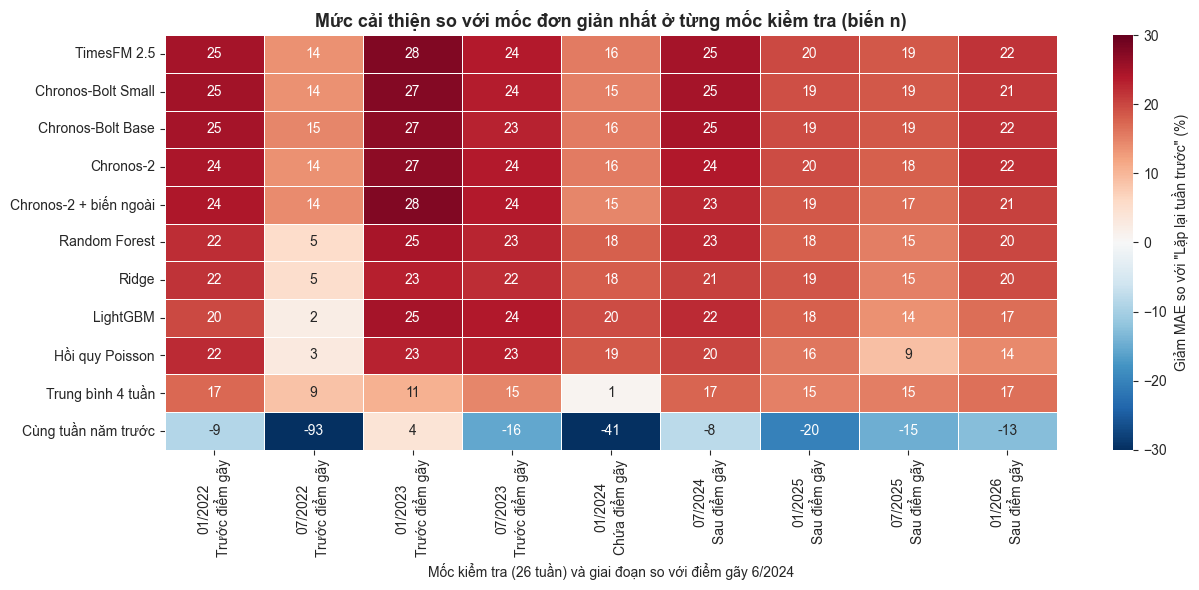

In [15]:
# Biểu đồ 1: mức giảm MAE so với "Lặp lại tuần trước" ở từng mốc (ô đỏ đậm = tốt hơn nhiều)
naive = chinh[chinh["mo_hinh"] == "Lặp lại tuần trước"].groupby("moc")["sai_so"].mean()
skill = (1 - chinh.groupby(["mo_hinh", "moc"])["sai_so"].mean().unstack() / naive) * 100
skill = skill.loc[[m for m in tong_hop["mo_hinh"] if m != "Lặp lại tuần trước"]]
skill.columns = [f"{c.strftime('%m/%Y')}\n{GIAI_DOAN[c]}" for c in skill.columns]

plt.figure(figsize=(13, 6))
sns.heatmap(skill, annot=True, fmt=".0f", cmap="RdBu_r", center=0, vmin=-30, vmax=30, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Giảm MAE so với \"Lặp lại tuần trước\" (%)"})
plt.xlabel("Mốc kiểm tra (26 tuần) và giai đoạn so với điểm gãy 6/2024")
plt.ylabel("")
plt.title("Mức cải thiện so với mốc đơn giản nhất ở từng mốc kiểm tra (biến n)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_b01_skill_by_origin.png", dpi=300)
plt.show()

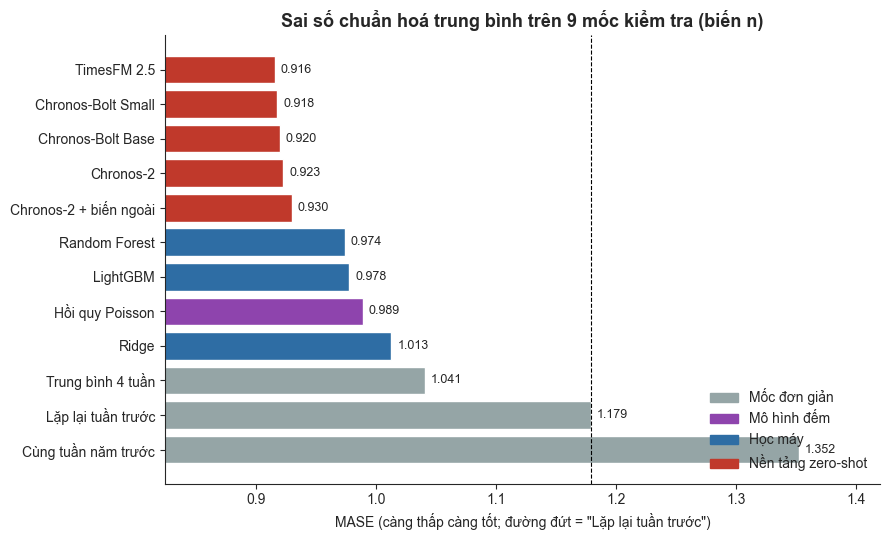

In [18]:
# Biểu đồ 2: MASE trung bình trên 9 mốc, tô màu theo họ mô hình
r = tong_hop.sort_values("MASE", ascending=False)
plt.figure(figsize=(9, 5.5))
plt.barh(r["mo_hinh"], r["MASE"], color=[MAU_HO[h] for h in r["ho"]])
mase_naive = r.loc[r["mo_hinh"] == "Lặp lại tuần trước", "MASE"].iloc[0]
plt.axvline(mase_naive, color="black", linestyle="--", linewidth=0.8)
for y, v in enumerate(r["MASE"]):
    plt.text(v + 0.005, y, f"{v:.3f}", va="center", fontsize=9)
from matplotlib.patches import Patch
chu_thich = [Patch(color=mau, label=ho) for ho, mau in MAU_HO.items()]
sns.despine()
plt.xlabel("MASE (càng thấp càng tốt; đường đứt = \"Lặp lại tuần trước\")")
plt.xlim(r["MASE"].min() * 0.9, r["MASE"].max() * 1.05)
plt.title("Sai số chuẩn hoá trung bình trên 9 mốc kiểm tra (biến n)", fontsize=13, fontweight="bold")
plt.legend(handles=chu_thich, frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_b02_mase_overall.png", dpi=300)
plt.show()

**Nhận xét:** Sai số tổng hợp trên 9 mốc

**Vì sao làm bước này?** Notebook 5 chỉ so sánh trên một lần chia dữ liệu. Ở đây mọi mô hình được đánh giá trên **cùng 9 mốc × 26 tuần**, với tham số chọn trước giai đoạn kiểm tra; heatmap cho thấy thứ hạng có ổn định qua các mốc hay không, còn MASE so sánh công bằng giữa khu phố ít và nhiều yêu cầu.

**Kết quả cần đọc:**
- **Mô hình nền tảng zero-shot chiếm cả 5 vị trí dẫn đầu**: TimesFM 2.5 tốt nhất (MAE **2.393**, giảm **21.4%** sai số so với "Lặp lại tuần trước", MASE **0.916**), tiếp theo là Chronos-Bolt Small, Chronos-Bolt Base và Chronos-2 (MAE 2.397–2.403) — bốn mô hình nền tảng chênh nhau chưa tới 0.5%.
- Mô hình huấn luyện riêng tốt nhất là **Random Forest** (MAE **2.462**, giảm **19.2%**); như vậy mô hình nền tảng tốt nhất có sai số thấp hơn khoảng **2.8%**, dù **không được huấn luyện trên dữ liệu San Francisco**.
- Mô hình nền tảng có MAE thấp nhất ở **7/9 mốc**; hai mốc còn lại thuộc về LightGBM, trong đó có **mốc 01/2024 — mốc chứa điểm gãy**.
- Khác biệt lớn nhất ở **mốc 07/2022** (giai đoạn ít biến động): mô hình nền tảng giảm 14–15% sai số so với mốc đơn giản nhất, trong khi mô hình huấn luyện riêng chỉ giảm 2–5%.
- Theo **RMSE** — chỉ số phạt nặng các sai số lớn — hai nhóm gần như ngang nhau (Ridge **4.275**, TimesFM 2.5 **4.284**): lợi thế của mô hình nền tảng nằm chủ yếu ở các tuần bình thường, không phải ở các tuần đột biến.
- **Thêm biến ngoài không giúp Chronos-2** (MAE 2.403 → 2.418) — kiểm tra chi tiết ở mục 7.

### Kiểm định thống kê

So sánh mô hình tốt nhất (MAE thấp nhất) với từng mô hình còn lại bằng **kiểm định Wilcoxon** trên sai số trung bình mỗi tuần (gộp 9 mốc × 26 tuần = 234 tuần), hiệu chỉnh nhiều phép so sánh bằng **phương pháp Holm**.

In [19]:
def holm(p):
    """Hiệu chỉnh Holm cho danh sách p-value."""
    p = np.asarray(p, dtype=float)
    thu_tu = np.argsort(p)
    m = len(p)
    p_hc = np.empty(m)
    tich_luy = 0
    for k, i in enumerate(thu_tu):
        tich_luy = max(tich_luy, min(1, (m - k) * p[i]))
        p_hc[i] = tich_luy
    return p_hc

tuan_sai_so = chinh.groupby(["moc", "week_start", "mo_hinh"])["sai_so"].mean().unstack()
tot_nhat = tong_hop["mo_hinh"].iloc[0]
rows = []
for ten in tong_hop["mo_hinh"].iloc[1:]:
    _, p = wilcoxon(tuan_sai_so[tot_nhat], tuan_sai_so[ten])
    rows.append({"so_sanh": f"{tot_nhat} vs {ten}",
                 "ty_le_tuan_tot_hon_%": round((tuan_sai_so[tot_nhat] < tuan_sai_so[ten]).mean() * 100, 1),
                 "p_value": p})
kiem_dinh = pd.DataFrame(rows)
kiem_dinh["p_holm"] = holm(kiem_dinh["p_value"])
kiem_dinh["co_y_nghia_5%"] = kiem_dinh["p_holm"] < 0.05
print(f"Số tuần so sánh: {len(tuan_sai_so)}")
kiem_dinh

Số tuần so sánh: 234


,so_sanh,ty_le_tuan_tot_hon_%,p_value,p_holm,co_y_nghia_5%
0,TimesFM 2.5 vs Chronos-Bolt Small,49.1,3.617200e-01,8.534558e-01,False
1,TimesFM 2.5 vs Chronos-Bolt Base,54.3,2.844853e-01,8.534558e-01,False
2,TimesFM 2.5 vs Chronos-2,53.4,2.972622e-01,8.534558e-01,False
3,TimesFM 2.5 vs Chronos-2 + biến ngoài,58.5,2.189109e-03,8.756435e-03,True
4,TimesFM 2.5 vs Random Forest,65.8,1.678033e-07,8.390166e-07,True
5,TimesFM 2.5 vs Ridge,66.2,1.375222e-07,8.251332e-07,True
6,TimesFM 2.5 vs LightGBM,65.8,5.496555e-08,3.847588e-07,True
7,TimesFM 2.5 vs Hồi quy Poisson,70.5,8.701331e-13,6.961065e-12,True
8,TimesFM 2.5 vs Trung bình 4 tuần,73.9,1.726407e-16,1.553766e-15,True
9,TimesFM 2.5 vs Lặp lại tuần trước,92.3,5.505897e-34,5.505897e-33,True


### Theo nhóm khu phố

Ba nhóm khu phố chia theo nhu cầu trung bình mỗi tuần trên tập huấn luyện (mỗi nhóm khoảng 1/3 số khu phố). Nhóm "Thấp" gồm các khu có nhiều tuần bằng 0 (Notebook 3, truy vấn 9).

In [20]:
nhom_rows = []
for (ten, nhom), g in chinh.groupby(["mo_hinh", "nhom_khu_pho"], observed=True):
    nhom_rows.append({"mo_hinh": ten, "nhom_khu_pho": nhom, "MASE": mase(g)})
theo_nhom = pd.DataFrame(nhom_rows).pivot(index="mo_hinh", columns="nhom_khu_pho", values="MASE")
theo_nhom = theo_nhom[["Thấp", "Trung bình", "Cao"]].loc[tong_hop["mo_hinh"]].round(3)
theo_nhom

nhom_khu_pho,Thấp,Trung bình,Cao
mo_hinh,,,
TimesFM 2.5,0.910,0.913,0.924
Chronos-Bolt Small,0.918,0.914,0.922
Chronos-Bolt Base,0.923,0.911,0.924
Chronos-2,0.926,0.920,0.923
Chronos-2 + biến ngoài,0.936,0.925,0.929
Random Forest,1.033,0.939,0.948
Ridge,1.156,0.934,0.941
LightGBM,1.025,0.946,0.961
Hồi quy Poisson,1.022,0.972,0.972


In [21]:
# Mô hình tốt nhất của từng nhóm khu phố
for nhom in ["Thấp", "Trung bình", "Cao"]:
    print(f"Nhóm {nhom:10s}: tốt nhất là {theo_nhom[nhom].idxmin()} (MASE {theo_nhom[nhom].min():.3f})")

Nhóm Thấp      : tốt nhất là TimesFM 2.5 (MASE 0.910)
Nhóm Trung bình: tốt nhất là Chronos-Bolt Base (MASE 0.911)
Nhóm Cao       : tốt nhất là Chronos-Bolt Small (MASE 0.922)


**Nhận xét:** Kiểm định và nhóm khu phố

**Vì sao làm bước này?** Chênh lệch MAE nhỏ có thể chỉ do ngẫu nhiên, nên kiểm định Wilcoxon theo từng tuần (có hiệu chỉnh Holm vì so sánh nhiều cặp) cho biết chênh lệch nào đáng tin. Tách theo nhóm khu phố cho biết mô hình thắng nhờ khu nhiều yêu cầu hay thắng đều ở mọi nhóm.

**Kết quả cần đọc:**
- **TimesFM 2.5 tốt hơn có ý nghĩa thống kê so với mọi mô hình huấn luyện riêng**: tốt hơn Random Forest, Ridge và LightGBM ở khoảng **66%** số tuần (p sau hiệu chỉnh Holm < 0.000001), và tốt hơn hồi quy Poisson ở **70.5%** số tuần.
- **Giữa các mô hình nền tảng không có khác biệt có ý nghĩa** (TimesFM 2.5 so với Chronos-Bolt Small, Chronos-Bolt Base, Chronos-2: p sau hiệu chỉnh = 0.85) — lợi thế thuộc về **cả họ mô hình nền tảng**, không riêng một mô hình.
- **Mô hình nền tảng dẫn đầu ở cả ba nhóm khu phố**, và lợi thế **lớn nhất ở nhóm nhu cầu thấp**: MASE **0.910–0.936** so với **1.025–1.156** của các mô hình huấn luyện riêng; riêng Ridge (1.156) còn kém hơn mốc "Trung bình 4 tuần" (1.095).
- Ở nhóm trung bình và cao, khoảng cách thu hẹp (tốt nhất 0.911 so với 0.934, và 0.922 so với 0.941).
- → Mô hình huấn luyện riêng gặp khó nhất ở các khu phố **số đếm nhỏ, nhiều tuần bằng 0** — đúng nơi mô hình nền tảng, học từ rất nhiều chuỗi thời gian khác nhau, cho dự báo ổn định hơn.

## **6. Tác động của điểm gãy và tái huấn luyện định kỳ — trả lời RQ3**

Sai số được gộp theo ba giai đoạn ở Notebook 6: **trước điểm gãy** (4 mốc), **chứa điểm gãy** (1 mốc), **sau điểm gãy** (4 mốc). Vì mức nhu cầu mỗi giai đoạn khác nhau, so sánh bằng **mức giảm MAE so với "Lặp lại tuần trước"** trong cùng giai đoạn.

In [22]:
mae_gd = chinh.groupby(["mo_hinh", "giai_doan"])["sai_so"].mean().unstack()
theo_giai_doan = ((1 - mae_gd / mae_gd.loc["Lặp lại tuần trước"]) * 100)
theo_giai_doan = theo_giai_doan[["Trước điểm gãy", "Chứa điểm gãy", "Sau điểm gãy"]]
theo_giai_doan = theo_giai_doan.loc[[m for m in tong_hop["mo_hinh"] if m != "Lặp lại tuần trước"]].round(1)
theo_giai_doan["thay_doi_sau_so_voi_truoc"] = (theo_giai_doan["Sau điểm gãy"] - theo_giai_doan["Trước điểm gãy"]).round(1)
theo_giai_doan

giai_doan,Trước điểm gãy,Chứa điểm gãy,Sau điểm gãy,thay_doi_sau_so_voi_truoc
mo_hinh,,,,
TimesFM 2.5,23.5,15.5,21.0,-2.5
Chronos-Bolt Small,23.4,15.2,20.8,-2.6
Chronos-Bolt Base,23.2,15.7,20.8,-2.4
Chronos-2,23.1,15.5,20.7,-2.4
Chronos-2 + biến ngoài,23.4,14.6,19.5,-3.9
Random Forest,20.0,17.9,18.7,-1.3
Ridge,19.2,18.2,18.3,-0.9
LightGBM,19.2,19.5,17.3,-1.9
Hồi quy Poisson,19.2,18.5,14.5,-4.7


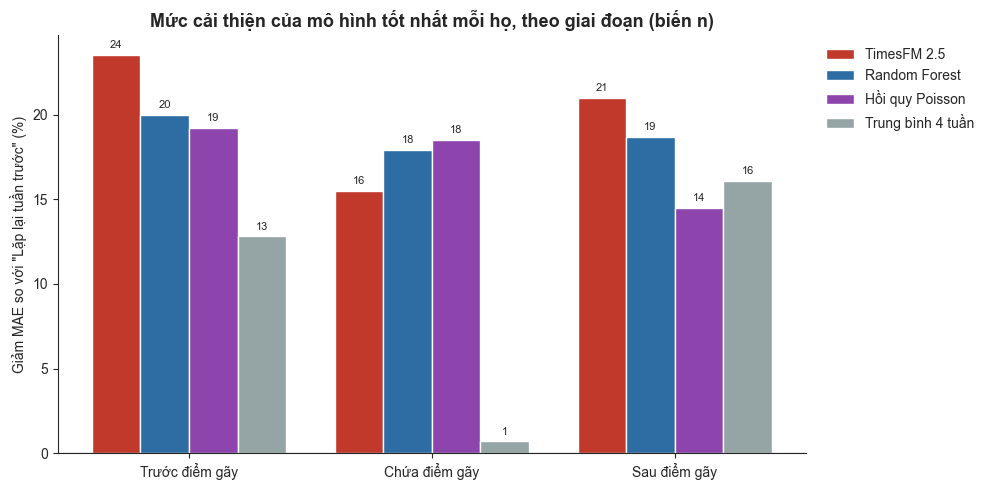

In [23]:
# Biểu đồ 3: mức cải thiện trước và sau điểm gãy, mỗi họ lấy mô hình tốt nhất (theo MAE chung)
dai_dien = tong_hop[tong_hop["mo_hinh"] != "Lặp lại tuần trước"].groupby("ho").head(1)["mo_hinh"].tolist()
d = theo_giai_doan.loc[dai_dien, ["Trước điểm gãy", "Chứa điểm gãy", "Sau điểm gãy"]]

x = np.arange(len(d.columns))
w = 0.8 / len(d)
plt.figure(figsize=(10, 5))
for i, ten in enumerate(d.index):
    plt.bar(x + i * w - 0.4 + w / 2, d.loc[ten], width=w, color=MAU_HO[HO_MO_HINH[ten]], label=ten)
    for xi, v in zip(x + i * w - 0.4 + w / 2, d.loc[ten]):
        plt.text(xi, v + (0.4 if v >= 0 else -1.2), f"{v:.0f}", ha="center", fontsize=8)
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(x, d.columns)
sns.despine()
plt.ylabel("Giảm MAE so với \"Lặp lại tuần trước\" (%)")
plt.title("Mức cải thiện của mô hình tốt nhất mỗi họ, theo giai đoạn (biến n)", fontsize=13, fontweight="bold")
plt.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_b03_skill_by_regime.png", dpi=300)
plt.show()

### Tái huấn luyện định kỳ

Mô hình nền tảng tự "cập nhật" mỗi tuần vì luôn nhận chuỗi mới nhất làm ngữ cảnh, còn mô hình huấn luyện riêng thì **cố định** từ lúc huấn luyện ở đầu mốc. Thử nghiệm: trong mỗi đoạn kiểm tra 26 tuần, **huấn luyện lại Ridge và LightGBM mỗi 4 tuần** bằng mọi dữ liệu đã biết đến lúc đó (vẫn chừa 1 tuần đệm), rồi so với bản cố định.

In [24]:
t0 = time.time()
tai_rows = []
for ten in ["Ridge", "LightGBM"]:
    tham_so = THAM_SO_TOT[("n", ten)]
    for moc in MOC_KIEM_TRA:
        _, test = chia_du_lieu("n", moc)
        tuan = sorted(test["week_start"].unique())
        pred = pd.Series(np.nan, index=test.index)
        for i in range(0, len(tuan), 4):
            bat_dau = pd.Timestamp(tuan[i])
            khoi = test["week_start"].isin(tuan[i:i + 4])
            train_moi, _ = chia_du_lieu("n", bat_dau)
            pred[khoi] = huan_luyen_du_bao(ten, train_moi, test[khoi], "n", tham_so)
        tai_rows.append(bang_du_bao(test, "n", moc, f"{ten} tái huấn luyện mỗi 4 tuần", pred.values))
print(f"Xong sau {(time.time() - t0) / 60:.1f} phút")

tai = pd.concat(tai_rows, ignore_index=True)
tai["sai_so"] = (tai["y"] - tai["du_bao"]).abs()
tai["giai_doan"] = tai["moc"].map(GIAI_DOAN)
so_sanh = pd.concat([chinh[chinh["mo_hinh"].isin(["Ridge", "LightGBM", "Lặp lại tuần trước"])], tai])
mae_tai = so_sanh.groupby(["mo_hinh", "giai_doan"])["sai_so"].mean().unstack()
mae_tai = mae_tai[["Trước điểm gãy", "Chứa điểm gãy", "Sau điểm gãy"]]
mae_tai["Cả 9 mốc"] = so_sanh.groupby("mo_hinh")["sai_so"].mean()
mae_tai.round(3)

Xong sau 0.9 phút


giai_doan,Trước điểm gãy,Chứa điểm gãy,Sau điểm gãy,Cả 9 mốc
mo_hinh,,,,
LightGBM,2.276,2.401,2.718,2.486
LightGBM tái huấn luyện mỗi 4 tuần,2.283,2.391,2.692,2.477
Lặp lại tuần trước,2.818,2.984,3.288,3.045
Ridge,2.276,2.440,2.686,2.476
Ridge tái huấn luyện mỗi 4 tuần,2.271,2.439,2.673,2.468


In [25]:
# Mức giảm MAE nhờ tái huấn luyện và kiểm định Wilcoxon theo tuần
rows = []
tuan_tai = so_sanh.groupby(["moc", "week_start", "mo_hinh"])["sai_so"].mean().unstack()
for ten in ["Ridge", "LightGBM"]:
    moi = f"{ten} tái huấn luyện mỗi 4 tuần"
    _, p = wilcoxon(tuan_tai[ten], tuan_tai[moi])
    rows.append({"mo_hinh": ten,
                 **{f"giam_MAE_{gd}_%": round((1 - mae_tai.loc[moi, gd] / mae_tai.loc[ten, gd]) * 100, 1)
                    for gd in ["Trước điểm gãy", "Chứa điểm gãy", "Sau điểm gãy", "Cả 9 mốc"]},
                 "ty_le_tuan_tot_hon_%": round((tuan_tai[moi] < tuan_tai[ten]).mean() * 100, 1),
                 "p_value": p})
tai_huan_luyen = pd.DataFrame(rows)
tai_huan_luyen

,mo_hinh,giam_MAE_Trước điểm gãy_%,giam_MAE_Chứa điểm gãy_%,giam_MAE_Sau điểm gãy_%,giam_MAE_Cả 9 mốc_%,ty_le_tuan_tot_hon_%,p_value
0,Ridge,0.2,0.0,0.5,0.3,58.5,7.093781e-08
1,LightGBM,-0.3,0.4,1.0,0.4,49.1,7.807094e-02


**Nhận xét:** Tác động của điểm gãy và tái huấn luyện

**Vì sao làm bước này?** Notebook 6 cho thấy dữ liệu có hai thay đổi nối tiếp nhau: đổi cách phân loại (6/2024) và tổng số yêu cầu tăng mạnh (từ giữa 2025). Nếu mô hình huấn luyện riêng bị "kẹt" ở mức nhu cầu cũ, lợi thế của nó sẽ giảm sau điểm gãy, và tái huấn luyện định kỳ sẽ giúp lấy lại một phần.

**Kết quả cần đọc:**
- **Trước điểm gãy** (4 mốc), mô hình nền tảng giảm **23–23.5%** sai số so với "Lặp lại tuần trước", hơn các mô hình học máy (**19–20%**) khoảng 3.5 điểm %.
- **Sau điểm gãy** (4 mốc), thứ hạng giữ nguyên: mô hình nền tảng giảm **21%**, học máy **17–19%**. Mọi mô hình đều giảm nhẹ mức cải thiện; mô hình nền tảng giảm khoảng **2.5 điểm %**, hồi quy Poisson giảm nhiều nhất (**4.7 điểm %**).
- **Mốc chứa điểm gãy (01/2024)** là mốc duy nhất mô hình học máy thắng (giảm **18–19.5%** so với **15–16%**). Tuy vậy, mốc này cũng chứa **hai trận bão lớn** (cuối tháng 1 và đầu tháng 2/2024, nằm trong 5 tuần cao nhất ở Notebook 4), nên không tách riêng được tác động của điểm gãy; mốc "Trung bình 4 tuần" ở đây gần như không cải thiện gì (**0.7%**), cho thấy mọi mô hình chỉ dựa vào lịch sử gần đây đều gặp khó.
- **Tái huấn luyện mỗi 4 tuần chỉ giúp rất ít**: Ridge giảm **0.3%** sai số (có ý nghĩa, p < 0.0001), LightGBM giảm **0.4%** (không có ý nghĩa, p = 0.078); lợi ích rõ hơn sau điểm gãy (0.5% và 1.0%) nhưng vẫn nhỏ. Ridge đã tái huấn luyện (MAE **2.468**) vẫn kém TimesFM 2.5 (**2.393**).
- → Điểm gãy làm mọi mô hình kém đi một chút nhưng **không đảo ngược thứ hạng**. Vì thiết kế 9 mốc đã huấn luyện lại mô hình mỗi 6 tháng, tái huấn luyện dày hơn gần như không thêm lợi ích; mô hình nền tảng, vốn tự cập nhật qua ngữ cảnh mỗi tuần, vẫn dẫn đầu.

## **7. Dữ liệu ngoài có giúp dự báo không — trả lời RQ2**

Hai thử nghiệm:
1. **LightGBM bỏ từng nhóm đặc trưng** (dùng lại tham số tốt nhất), đo MAE trên 9 mốc. Thêm cấu hình **chỉ giữ lịch sử nhu cầu, tháng và khu phố** (bỏ cả thời tiết, giấy phép và đặc điểm cây).
2. **Chronos-2 có và không có biến ngoài** (đã chạy ở mục 4).

In [26]:
t0 = time.time()
nhom = nhom_dac_trung("n")
cau_hinh = {"Đầy đủ đặc trưng": tat_ca_dac_trung("n")}
for ten_nhom, cols in nhom.items():
    cau_hinh[f"Bỏ {ten_nhom.lower()}"] = [c for c in tat_ca_dac_trung("n") if c not in cols]
cau_hinh["Chỉ lịch sử, tháng và khu phố"] = nhom["Lịch sử nhu cầu"] + nhom["Lịch (tháng)"] + nhom["Khu phố"]

ab_rows = []
for ten_ch, cols in cau_hinh.items():
    sai_so = []
    for moc in MOC_KIEM_TRA:
        train, test = chia_du_lieu("n", moc)
        pred = huan_luyen_du_bao("LightGBM", train, test, "n", THAM_SO_TOT[("n", "LightGBM")], cols=cols)
        sai_so.append(np.abs(test["y_next"].values - pred))
    ab_rows.append({"cau_hinh": ten_ch, "so_dac_trung": len(cols), "MAE": np.concatenate(sai_so).mean()})
bo_dac_trung = pd.DataFrame(ab_rows)
bo_dac_trung["thay_doi_MAE_%"] = (bo_dac_trung["MAE"] / bo_dac_trung["MAE"].iloc[0] - 1) * 100
print(f"Xong sau {(time.time() - t0) / 60:.1f} phút")
bo_dac_trung.round(3)

Xong sau 0.9 phút


,cau_hinh,so_dac_trung,MAE,thay_doi_MAE_%
0,Đầy đủ đặc trưng,14,2.486,0.000
1,Bỏ lịch sử nhu cầu,9,2.715,9.205
2,Bỏ giấy phép thi công,13,2.485,-0.043
3,Bỏ thời tiết,11,2.473,-0.538
4,Bỏ đặc điểm cây,11,2.515,1.145
5,Bỏ lịch (tháng),13,2.470,-0.673
6,Bỏ khu phố,13,2.486,-0.009
7,"Chỉ lịch sử, tháng và khu phố",7,2.496,0.401


In [27]:
# Chronos-2 có và không có biến ngoài
c2 = chinh[chinh["mo_hinh"].isin(["Chronos-2", "Chronos-2 + biến ngoài"])]
if c2["mo_hinh"].nunique() == 2:
    c2_bang = c2.groupby(["mo_hinh", "giai_doan"])["sai_so"].mean().unstack()[["Trước điểm gãy", "Chứa điểm gãy", "Sau điểm gãy"]]
    c2_bang["Cả 9 mốc"] = c2.groupby("mo_hinh")["sai_so"].mean()
    tuan_c2 = c2.groupby(["moc", "week_start", "mo_hinh"])["sai_so"].mean().unstack()
    _, p = wilcoxon(tuan_c2["Chronos-2"], tuan_c2["Chronos-2 + biến ngoài"])
    print(f"Thêm biến ngoài tốt hơn ở {(tuan_c2['Chronos-2 + biến ngoài'] < tuan_c2['Chronos-2']).mean() * 100:.1f}% số tuần, "
          f"Wilcoxon p-value = {p:.4f}")
    display(c2_bang.round(3))

Thêm biến ngoài tốt hơn ở 36.3% số tuần, Wilcoxon p-value = 0.0006


giai_doan,Trước điểm gãy,Chứa điểm gãy,Sau điểm gãy,Cả 9 mốc
mo_hinh,,,,
Chronos-2,2.167,2.521,2.609,2.403
Chronos-2 + biến ngoài,2.157,2.549,2.647,2.418


**Nhận xét:** Dữ liệu ngoài và dự báo

**Vì sao làm bước này?** Notebook 4 cho thấy thời tiết và giấy phép thi công chỉ liên quan yếu đến nhu cầu, còn Notebook 5 (một lần chia dữ liệu) cho thấy bỏ chúng đi không làm dự báo kém hơn. Ở đây kiểm tra lại trên 9 mốc, và kiểm tra thêm với một mô hình nền tảng có khả năng nhận biến ngoài.

**Kết quả cần đọc:**
- **Lịch sử nhu cầu là nhóm đặc trưng duy nhất thật sự cần thiết**: bỏ đi thì sai số của LightGBM tăng **9.2%**.
- **Thời tiết, giấy phép thi công, tháng và khu phố không giúp gì**: bỏ từng nhóm làm MAE thay đổi dưới **0.7%** (thậm chí giảm nhẹ khi bỏ thời tiết hoặc tháng), nằm trong mức dao động giữa các lần chạy của LightGBM (khoảng 0.4%, Notebook 5). Chỉ giữ lịch sử nhu cầu, tháng và khu phố (7 thay vì 14 đặc trưng) cũng chỉ làm sai số tăng **0.4%**.
- **Đặc điểm cây giúp một chút** (bỏ đi sai số tăng **1.1%**) — ngược với Notebook 5, nơi bỏ nhóm này lại làm sai số giảm 2.7%. Khác biệt đến từ việc đặc điểm cây giờ được tính tại mốc 03/01/2022 (Notebook 2) thay vì từ danh mục năm 2026 có lẫn các cây trồng trong giai đoạn kiểm tra; số cây bây giờ chỉ đóng vai trò cho biết quy mô của khu phố.
- **Thêm biến ngoài làm Chronos-2 kém hơn có ý nghĩa thống kê**: MAE tăng từ **2.403** lên **2.418**, cấu hình có biến ngoài chỉ tốt hơn ở **36.3%** số tuần (Wilcoxon p = 0.0006). Trước điểm gãy hai cấu hình gần như ngang nhau (2.157 so với 2.167); sau điểm gãy, biến ngoài làm sai số tăng rõ hơn (2.609 → 2.647).
- → Cả mô hình huấn luyện riêng lẫn mô hình nền tảng đều cho cùng một kết luận: với dự báo **một tuần tới**, thời tiết và giấy phép thi công **không mang thêm thông tin hữu ích** ngoài chính lịch sử nhu cầu — khớp với tương quan yếu ở Notebook 4.

## **8. Kiểm tra trên hai biến mục tiêu khác**

Lặp lại so sánh cho `n_all` (giữ cả yêu cầu trùng) và `n_damaged` (chỉ loại "cây hư hại" — loại ít bị ảnh hưởng bởi điểm gãy, Notebook 6). Nếu thứ hạng các mô hình giữ nguyên, kết luận ở mục 5 không phụ thuộc vào cách định nghĩa biến mục tiêu.

In [28]:
ben_rows = []
for bien in BIEN_DEM:
    t = bang_tong_hop(du_bao[du_bao["bien"] == bien])
    t["bien"] = bien
    t["hang"] = t["MAE"].rank(method="min").astype(int)
    ben_rows.append(t)
ben_vung = pd.concat(ben_rows, ignore_index=True)
bang_hang = ben_vung.pivot(index="mo_hinh", columns="bien", values="hang")[list(BIEN_DEM)]
bang_mase = ben_vung.pivot(index="mo_hinh", columns="bien", values="MASE")[list(BIEN_DEM)]
ket_hop = bang_mase.round(3).astype(str) + " (" + bang_hang.astype("Int64").astype(str) + ")"
ket_hop = ket_hop.loc[tong_hop["mo_hinh"]]
ket_hop.columns = [TEN_BIEN[b] for b in ket_hop.columns]
print("MASE trên 9 mốc (thứ hạng theo MAE trong ngoặc); Chronos-2 + biến ngoài chỉ chạy cho biến n")
ket_hop

MASE trên 9 mốc (thứ hạng theo MAE trong ngoặc); Chronos-2 + biến ngoài chỉ chạy cho biến n


,n (đã loại trùng),n_all (giữ cả trùng),n_damaged (cây hư hại)
mo_hinh,,,
TimesFM 2.5,0.916 (1),0.903 (1),0.83 (1)
Chronos-Bolt Small,0.918 (2),0.905 (2),0.836 (4)
Chronos-Bolt Base,0.92 (2),0.907 (3),0.836 (3)
Chronos-2,0.923 (4),0.911 (4),0.832 (2)
Chronos-2 + biến ngoài,0.93 (5),nan (<NA>),nan (<NA>)
Random Forest,0.974 (6),0.972 (5),0.961 (8)
Ridge,1.013 (7),1.012 (7),1.016 (7)
LightGBM,0.978 (8),0.983 (6),0.953 (6)
Hồi quy Poisson,0.989 (9),0.983 (8),0.941 (5)


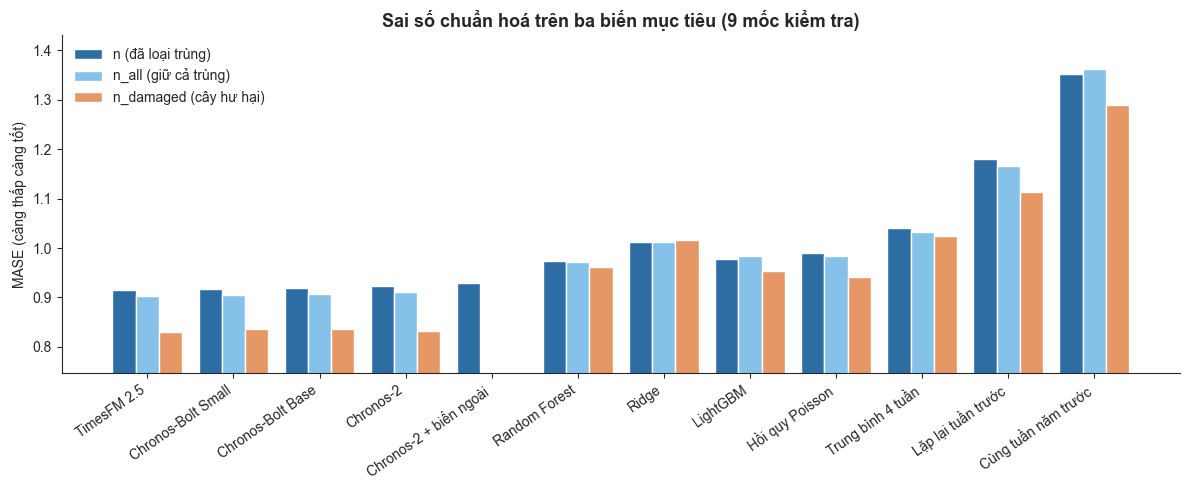

In [29]:
# Biểu đồ 4: MASE của mỗi mô hình trên ba biến mục tiêu
d = bang_mase.loc[[m for m in tong_hop["mo_hinh"] if m in bang_mase.index]]
x = np.arange(len(d))
w = 0.27
plt.figure(figsize=(12, 5))
for i, (bien, mau) in enumerate(zip(BIEN_DEM, ["#2E6DA4", "#85C1E9", "#E59866"])):
    plt.bar(x + (i - 1) * w, d[bien], width=w, color=mau, label=TEN_BIEN[bien])
plt.xticks(x, d.index, rotation=35, ha="right")
sns.despine()
plt.ylabel("MASE (càng thấp càng tốt)")
plt.ylim(d.min().min() * 0.9, d.max().max() * 1.05)
plt.title("Sai số chuẩn hoá trên ba biến mục tiêu (9 mốc kiểm tra)", fontsize=13, fontweight="bold")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("../Outputs/figures/fig_b04_mase_three_targets.png", dpi=300)
plt.show()

**Nhận xét:** Ba biến mục tiêu

**Vì sao làm bước này?** Biến mục tiêu chính `n` phụ thuộc vào hai quyết định: loại bỏ yêu cầu trùng (nhãn chỉ có sau khi xử lý) và gộp mọi loại yêu cầu (bị ảnh hưởng bởi điểm gãy). Lặp lại so sánh trên `n_all` và `n_damaged` kiểm tra xem kết luận có đứng vững khi thay đổi hai quyết định này không.

**Kết quả cần đọc:**
- **Kết luận ở mục 5 giữ nguyên trên cả ba biến mục tiêu**: TimesFM 2.5 đứng **thứ nhất** ở cả `n`, `n_all` và `n_damaged`, và bốn vị trí đầu ở cả ba biến đều là mô hình nền tảng.
- Với **`n_all`** (giữ cả yêu cầu trùng), MASE và thứ hạng gần như giống hệt `n` (TimesFM 2.5: **0.903** so với **0.916**) — việc loại hay giữ yêu cầu trùng không làm thay đổi kết luận.
- Với **`n_damaged`** — biến thưa nhất (39.6% số tuần bằng 0, Notebook 2) và ít bị ảnh hưởng bởi điểm gãy nhất (Notebook 6) — **lợi thế của mô hình nền tảng lớn hơn hẳn**: MASE **0.830–0.836**, so với **0.941** của mô hình huấn luyện riêng tốt nhất (hồi quy Poisson), tức sai số chuẩn hoá thấp hơn khoảng **11%**.
- → Mô hình nền tảng càng có lợi khi chuỗi **càng thưa và số đếm càng nhỏ** — khớp với kết quả theo nhóm khu phố ở mục 5.

## **9. Xuất bảng kết quả**

In [30]:
tune_df.to_csv("../Outputs/tables/bench_01_tuning.csv", index=False)
tong_hop.to_csv("../Outputs/tables/bench_02_overall.csv", index=False)
mae_theo_moc.to_csv("../Outputs/tables/bench_03_mae_by_origin.csv")
kiem_dinh.to_csv("../Outputs/tables/bench_04_wilcoxon_holm.csv", index=False)
theo_nhom.to_csv("../Outputs/tables/bench_05_mase_by_nbhd_group.csv")
theo_giai_doan.to_csv("../Outputs/tables/bench_06_skill_by_regime.csv")
tai_huan_luyen.to_csv("../Outputs/tables/bench_07_retraining.csv", index=False)
bo_dac_trung.to_csv("../Outputs/tables/bench_08_feature_ablation.csv", index=False)
ben_vung.to_csv("../Outputs/tables/bench_09_three_targets.csv", index=False)

# Bảng dự báo đầy đủ (kèm phân vị của mô hình nền tảng) dùng cho Notebook 8
du_bao.to_csv("../Data/processed/SF_Tree_Benchmark_Predictions.csv", index=False)
print("Đã lưu xong 4 biểu đồ, 9 bảng kết quả và bảng dự báo cho Notebook 8.")

Đã lưu xong 4 biểu đồ, 9 bảng kết quả và bảng dự báo cho Notebook 8.
